### Notebook 01: Quadcopter Dynamical Model

This notebook implements and validates the mathematical model of a four-rotor quadcopter developed for the AE 352 project.

The model includes six degrees of freedom (6-DOF), accounting for translational motion, rotational motion, gravity, and thrust generated by four rotors.

The complete model contains 16 state variables:

$$
\mathbf{x} =
[x,y,z,v_x,v_y,v_z,\phi,\theta,\psi,p,q,r,\omega_1,\omega_2,\omega_3,\omega_4]^T
$$

The governing equations are implemented in `drone_model.py`. This notebook verifies the physical parameters, rotor forces, and moments before numerically testing stationary hover.

In [3]:
import numpy as np
import matplotlib.pyplot as plt

from scipy.integrate import solve_ivp
import drone_model as drone

In [4]:
# Calculate hover conditions
hover_speed, hover_torque = drone.hover_conditions()

# Convert angular velocity to RPM
hover_rpm = hover_speed * 60 / (2 * np.pi)

# Calculate battery energy
battery_energy = (
    drone.BATTERY_VOLTAGE *
    drone.BATTERY_CAPACITY
)

usable_energy = battery_energy * (
    1 - drone.BATTERY_RESERVE
)

print("DRONE PARAMETERS")
print("-----------------------------")
print(f"Mass: {drone.MASS:.2f} kg")
print(f"Arm length: {drone.ARM_LENGTH:.3f} m")
print(f"Ix: {drone.IX:.5f} kg*m^2")
print(f"Iy: {drone.IY:.5f} kg*m^2")
print(f"Iz: {drone.IZ:.5f} kg*m^2")

print("\nHOVER EQUILIBRIUM")
print("-----------------------------")
print(f"Rotor speed: {hover_speed:.2f} rad/s")
print(f"Rotor speed: {hover_rpm:.2f} RPM")
print(f"Motor torque: {hover_torque:.5f} N*m")

print("\nBATTERY")
print("-----------------------------")
print(f"Nominal energy: {battery_energy:.2f} Wh")
print(f"Usable energy: {usable_energy:.2f} Wh")

DRONE PARAMETERS
-----------------------------
Mass: 1.20 kg
Arm length: 0.225 m
Ix: 0.00887 kg*m^2
Iy: 0.00887 kg*m^2
Iz: 0.01718 kg*m^2

HOVER EQUILIBRIUM
-----------------------------
Rotor speed: 445.93 rad/s
Rotor speed: 4258.29 RPM
Motor torque: 0.05588 N*m

BATTERY
-----------------------------
Nominal energy: 55.50 Wh
Usable energy: 44.40 Wh


In [5]:
hover_speed, hover_torque = drone.hover_conditions()
hover_rpm = hover_speed * 60 / (2 * np.pi)

battery_energy = drone.BATTERY_VOLTAGE * drone.BATTERY_CAPACITY
usable_energy = battery_energy * (1 - drone.BATTERY_RESERVE)

print("Mass:", drone.MASS, "kg")
print("Arm length:", drone.ARM_LENGTH, "m")
print("Moments of inertia:", drone.IX, drone.IY, drone.IZ)

print("Hover speed:", round(hover_speed, 2), "rad/s")
print("Hover RPM:", round(hover_rpm, 2))
print("Hover motor torque:", round(hover_torque, 5), "Nm")

print("Battery energy:", battery_energy, "Wh")
print("Usable energy:", round(usable_energy, 2), "Wh")

Mass: 1.2 kg
Arm length: 0.225 m
Moments of inertia: 0.00887 0.00887 0.01718
Hover speed: 445.93 rad/s
Hover RPM: 4258.29
Hover motor torque: 0.05588 Nm
Battery energy: 55.5 Wh
Usable energy: 44.4 Wh


In [6]:
rotor_speeds = np.array([hover_speed] * 4)

total_thrust, moments = drone.rotor_forces(rotor_speeds)
weight = drone.MASS * drone.GRAVITY

print("Total thrust:", round(total_thrust, 4), "N")
print("Weight:", round(weight, 4), "N")
print("Body moments:", moments)

assert np.isclose(total_thrust, weight)
assert np.allclose(moments, 0)

# Increase rotor 2 speed by 5%
modified_speeds = rotor_speeds.copy()
modified_speeds[1] *= 1.05

new_thrust, new_moments = drone.rotor_forces(modified_speeds)

print("Modified thrust:", round(new_thrust, 4), "N")
print("Modified moments:", new_moments)

assert new_moments[0] > 0
assert np.isclose(new_moments[1], 0)
assert new_moments[2] > 0

Total thrust: 11.772 N
Weight: 11.772 N
Body moments: [0. 0. 0.]
Modified thrust: 12.0737 N
Modified moments: [0.06787294 0.         0.00572742]


## Equations of Motion and Numerical Integration

The quadcopter's translational motion follows Newton's second law:

$$
m\ddot{\mathbf{r}} = TR\mathbf{e}_3 - mg\mathbf{e}_3
$$

Rotational motion is governed by Euler's rigid-body equations:

$$
I\dot{\boldsymbol{\Omega}} +
\boldsymbol{\Omega}\times(I\boldsymbol{\Omega}) =
\boldsymbol{\tau}
$$

Each rotor produces thrust according to $F_i = k\omega_i^2$, while motor torque determines rotor acceleration:

$$
J_r\dot{\omega}_i = u_i - b\omega_i^2
$$

Together, these equations form the 16-state system:

$$
\dot{\mathbf{x}} = f(t,\mathbf{x},\mathbf{u})
$$

We use SciPy's `solve_ivp` to integrate the equations for 120 seconds, starting at 1 m altitude with all four motors operating at their calculated hover equilibrium.

In [7]:
# Initial conditions
initial_state = np.zeros(16)
initial_state[2] = 1.0
initial_state[12:16] = hover_speed

motor_torques = np.array([hover_torque] * 4)

# Simulation time
time_points = np.linspace(0, 120, 601)

# Solve equations of motion
solution = solve_ivp(
    drone.drone_derivatives,
    (0, 120),
    initial_state,
    args=(motor_torques,),
    t_eval=time_points,
    rtol=1e-8,
    atol=1e-10,
    max_step=0.2
)

assert solution.success, solution.message

print("Solver successful:", solution.success)
print("Final position:", solution.y[0:3, -1])
print("Final Euler angles:", np.degrees(solution.y[6:9, -1]))

Solver successful: True
Final position: [0. 0. 1.]
Final Euler angles: [0. 0. 0.]


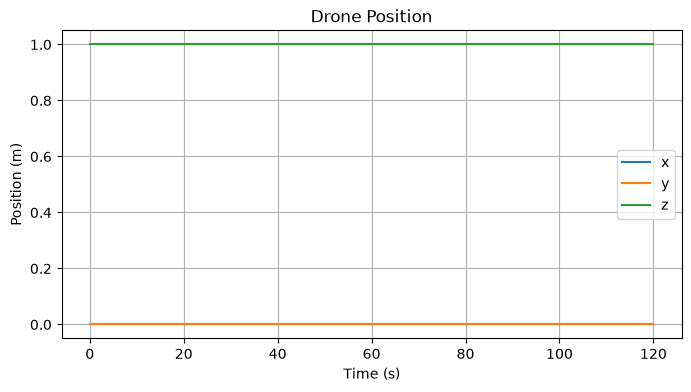

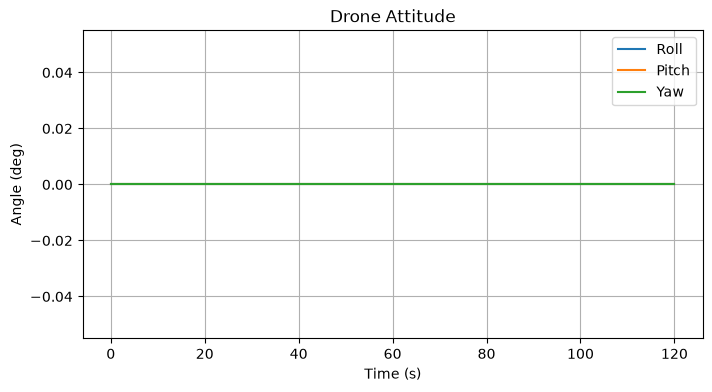

Altitude error: 0.0
Horizontal error: 0.0
Attitude error: 0.0
Average power: 143.43 W
Energy used: 4.781 Wh
Battery used: 10.77 %


In [8]:
time = solution.t

x = solution.y[0]
y = solution.y[1]
z = solution.y[2]

roll = np.degrees(solution.y[6])
pitch = np.degrees(solution.y[7])
yaw = np.degrees(solution.y[8])

# Position plot
plt.figure(figsize=(8, 4))
plt.plot(time, x, label="x")
plt.plot(time, y, label="y")
plt.plot(time, z, label="z")
plt.xlabel("Time (s)")
plt.ylabel("Position (m)")
plt.title("Drone Position")
plt.legend()
plt.grid()
plt.show()

# Attitude plot
plt.figure(figsize=(8, 4))
plt.plot(time, roll, label="Roll")
plt.plot(time, pitch, label="Pitch")
plt.plot(time, yaw, label="Yaw")
plt.xlabel("Time (s)")
plt.ylabel("Angle (deg)")
plt.title("Drone Attitude")
plt.legend()
plt.grid()
plt.show()

# Numerical errors
altitude_error = np.max(np.abs(z - 1.0))
horizontal_error = np.max(np.sqrt(x**2 + y**2))
attitude_error = np.max(np.abs(solution.y[6:9]))

print("Altitude error:", altitude_error)
print("Horizontal error:", horizontal_error)
print("Attitude error:", attitude_error)

assert altitude_error < 1e-5
assert horizontal_error < 1e-5
assert attitude_error < 1e-5

# Power and energy
power = []

for i in range(len(time)):
    speeds = solution.y[12:16, i]
    power.append(drone.electrical_power(speeds))

power = np.array(power)
energy = np.trapezoid(power, time) / 3600

print("Average power:", round(np.mean(power), 2), "W")
print("Energy used:", round(energy, 3), "Wh")
print("Battery used:", round(100 * energy / usable_energy, 2), "%")